In [1]:
%uv pip install -q transformers albumentations timm


Note: you may need to restart the kernel to use updated packages.


In [2]:
%uv pip install -q kagglehub

import kagglehub

# Download WHU Building Dataset
path = kagglehub.dataset_download("sengulgs/whu-building-dataset")
print(f"Dataset downloaded to: {path}")


Note: you may need to restart the kernel to use updated packages.
Dataset downloaded to: /root/.cache/kagglehub/datasets/sengulgs/whu-building-dataset/versions/1


In [3]:
import os
import random
import math
import numpy as np
from glob import glob
from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from transformers import SegformerForSemanticSegmentation, AutoImageProcessor
import albumentations as A
from tqdm import tqdm
import gc
import pandas as pd
import matplotlib.pyplot as plt


In [4]:
DATA_ROOT = "/root/.cache/kagglehub/datasets/sengulgs/whu-building-dataset/versions/1/WHU"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

IMG_SIZE = 512
BATCH_SIZE = 8
EPOCHS_PER_RATIO = 25     # 2 ratios × 20 epochs fits budget
LR = 6e-5
NUM_CLASSES = 2
NUM_WORKERS = 4

# Phase-2 loss weights
LAMBDA_KD = 0.5
LAMBDA_SCALE = 0.3
LAMBDA_BOUNDARY = 0.3
LAMBDA_UNSUP = 0.5
TEMPERATURE = 4.0
TAU = 0.6

# Multiple label ratios to test
LABEL_RATIOS = [0.1, 0.2]   # 10%, 20%

TEACHER_CKPT_PATHS = [
    "/root/best_segformer_mit_b1_epoch50_iou0.8283.pt",
    "/kaggle/input/models/parthivmandala/best-segformer-mit-b1-epoch50-iou0-8283-pt/pytorch/default/1/best_segformer_mit_b1_epoch50_iou0.8283.pt",
    "/kaggle/input/segformer-mit-b1-whu-building/pytorch/default/1/best_segformer_mit_b1_epoch50_iou0.8283.pt",
]
TEACHER_CKPT_PATH = None
for path in TEACHER_CKPT_PATHS:
    if os.path.exists(path):
        TEACHER_CKPT_PATH = path
        print(f"Found teacher checkpoint at: {path}")
        break
if TEACHER_CKPT_PATH is None:
    print("Teacher checkpoint not found")

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


Teacher checkpoint not found


In [5]:
class WHULabeledDataset(Dataset):
    def __init__(self, img_paths, mask_paths, image_processor, augment=None):
        self.imgs = img_paths
        self.masks = mask_paths
        self.processor = image_processor
        self.augment = augment
    def __len__(self):
        return len(self.imgs)
    def __getitem__(self, idx):
        img = np.array(Image.open(self.imgs[idx]).convert("RGB"))
        mask = np.array(Image.open(self.masks[idx]).convert("L"))
        mask = (mask > 127).astype(np.uint8)
        if self.augment:
            aug = self.augment(image=img, mask=mask)
            img, mask = aug["image"], aug["mask"]
        enc = self.processor(images=img, return_tensors="pt")
        pixel_values = enc.pixel_values.squeeze(0)
        mask = torch.from_numpy(mask).long()
        return pixel_values, mask

class WHUUnlabeledDataset(Dataset):
    def __init__(self, img_paths, image_processor, augment=None):
        self.imgs = img_paths
        self.processor = image_processor
        self.augment = augment
    def __len__(self):
        return len(self.imgs)
    def __getitem__(self, idx):
        img = np.array(Image.open(self.imgs[idx]).convert("RGB"))
        if self.augment:
            aug = self.augment(image=img)
            img = aug["image"]
        enc = self.processor(images=img, return_tensors="pt")
        pixel_values = enc.pixel_values.squeeze(0)
        return pixel_values

In [6]:
class MultiScaleFusionHead(nn.Module):
    def __init__(self, in_channels=[32, 64, 160, 256], out_channels=128):
        super().__init__()
        self.proj = nn.ModuleList([
            nn.Sequential(nn.Conv2d(c, out_channels, 1), nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True))
            for c in in_channels
        ])
        self.fuse = nn.Sequential(
            nn.Conv2d(out_channels * 4, out_channels, 3, padding=1), nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True), nn.Dropout2d(0.1),
            nn.Conv2d(out_channels, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.Dropout2d(0.1),
            nn.Conv2d(64, 2, 1)
        )
    def forward(self, features, target_size):
        resized = []
        for i, feat in enumerate(features):
            feat = self.proj[i](feat)
            feat = F.interpolate(feat, size=target_size, mode='bilinear', align_corners=False)
            resized.append(feat)
        return self.fuse(torch.cat(resized, dim=1))

class FeatureAdapter(nn.Module):
    def __init__(self, student_channels, teacher_channels):
        super().__init__()
        self.adapters = nn.ModuleList([nn.Conv2d(s, t, 1) for s, t in zip(student_channels, teacher_channels)])
        self.stage_weights = nn.Parameter(torch.tensor([0.5, 0.75, 1.0, 1.25]))
    def forward(self, student_feats, teacher_feats):
        loss, w_sum = 0.0, 0.0
        for i, (adapter, s, t) in enumerate(zip(self.adapters, student_feats, teacher_feats)):
            s_aligned = adapter(s)
            t_resized = F.adaptive_avg_pool2d(t, s.shape[-2:])
            s_norm = F.normalize(s_aligned, dim=1)
            t_norm = F.normalize(t_resized.detach(), dim=1)
            cos_loss = (1 - (s_norm * t_norm).sum(dim=1).mean())
            w = F.softplus(self.stage_weights[i])
            loss += w * cos_loss
            w_sum += w
        return loss / (w_sum + 1e-6)

def compute_boundary_mask(mask, kernel_size=3):
    mask_float = mask.float().unsqueeze(1)
    pad = kernel_size // 2
    dilated = F.max_pool2d(mask_float, kernel_size, stride=1, padding=pad)
    eroded = -F.max_pool2d(-mask_float, kernel_size, stride=1, padding=pad)
    return ((dilated - eroded).squeeze(1) > 0).float()

def boundary_loss(logits, targets, kernel_size=3):
    bm = compute_boundary_mask(targets, kernel_size)
    weight_map = 1.0 + 4.0 * bm
    return (F.cross_entropy(logits, targets, reduction='none') * weight_map).mean()

criterion_sup = nn.CrossEntropyLoss()

def kd_loss(student_logits, teacher_logits, T=TEMPERATURE, mask=None):
    s = F.log_softmax(student_logits / T, dim=1)
    t = F.softmax(teacher_logits / T, dim=1)
    kl = F.kl_div(s, t, reduction='none') * (T * T)
    if mask is not None:
        kl = kl * mask
    return kl.mean()

STUDENT_CHANNELS = [32, 64, 160, 256]
TEACHER_CHANNELS = [64, 128, 320, 512]

In [7]:
def evaluate_full_metrics(model, fusion, loader, device=DEVICE):
    model.eval(); fusion.eval()
    TP = FP = FN = TN = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            outputs = model(pixel_values=x, output_hidden_states=True)
            features = [outputs.hidden_states[i] for i in range(4)]
            logits = fusion(features, target_size=y.shape[-2:])
            preds = torch.argmax(logits, dim=1)
            TP += ((preds == 1) & (y == 1)).sum().item()
            FP += ((preds == 1) & (y == 0)).sum().item()
            FN += ((preds == 0) & (y == 1)).sum().item()
            TN += ((preds == 0) & (y == 0)).sum().item()
    eps = 1e-6
    return {
        'IoU': TP / (TP + FP + FN + eps),
        'Dice': (2*TP) / (2*TP + FP + FN + eps),
        'Precision': TP / (TP + FP + eps),
        'Recall': TP / (TP + FN + eps),
        'F1': 2*TP/(2*TP+FP+FN+eps),  # same as Dice for binary
        'Accuracy': (TP+TN) / (TP+TN+FP+FN+eps)
    }

def evaluate_iou(model, fusion, loader, device=DEVICE):
    return evaluate_full_metrics(model, fusion, loader, device)['IoU']

def evaluate_with_tta(model, fusion, loader, device=DEVICE):
    model.eval(); fusion.eval()
    TP = FP = FN = TN = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(pixel_values=x, output_hidden_states=True)
            feats = [out.hidden_states[i] for i in range(4)]
            logits_orig = fusion(feats, target_size=y.shape[-2:])
            x_h = torch.flip(x, dims=[3])
            out_h = model(pixel_values=x_h, output_hidden_states=True)
            logits_h = torch.flip(fusion([out_h.hidden_states[i] for i in range(4)], target_size=y.shape[-2:]), dims=[3])
            x_v = torch.flip(x, dims=[2])
            out_v = model(pixel_values=x_v, output_hidden_states=True)
            logits_v = torch.flip(fusion([out_v.hidden_states[i] for i in range(4)], target_size=y.shape[-2:]), dims=[2])
            preds = torch.argmax((logits_orig + logits_h + logits_v) / 3.0, dim=1)
            TP += ((preds == 1) & (y == 1)).sum().item()
            FP += ((preds == 1) & (y == 0)).sum().item()
            FN += ((preds == 0) & (y == 1)).sum().item()
            TN += ((preds == 0) & (y == 0)).sum().item()
    eps = 1e-6
    return {
        'IoU': TP / (TP + FP + FN + eps),
        'Dice': (2*TP) / (2*TP + FP + FN + eps),
        'Precision': TP / (TP + FP + eps),
        'Recall': TP / (TP + FN + eps),
        'F1': 2*TP/(2*TP+FP+FN+eps),
        'Accuracy': (TP+TN) / (TP+TN+FP+FN+eps)
    }

In [8]:
def find_image_mask_pairs(base_path, split_name='train'):
    images, masks = [], []
    for root, dirs, files in os.walk(base_path):
        if split_name not in root.lower():
            continue
        for file in sorted(files):
            if file.lower().endswith(('.png', '.jpg', '.jpeg', '.tif')):
                full_path = os.path.join(root, file)
                if 'mask' in root.lower() or 'mask' in file.lower():
                    masks.append(full_path)
                else:
                    images.append(full_path)
    return sorted(images), sorted(masks)

train_imgs, train_masks = find_image_mask_pairs(DATA_ROOT, 'train')
val_imgs, val_masks = find_image_mask_pairs(DATA_ROOT, 'val')
test_imgs, test_masks = find_image_mask_pairs(DATA_ROOT, 'test')
print(f"Train: {len(train_imgs)} | Val: {len(val_imgs)} | Test: {len(test_imgs)}")

all_train_pairs = list(zip(train_imgs, train_masks))
random.shuffle(all_train_pairs)
val_pairs = list(zip(val_imgs, val_masks))

from transformers import SegformerImageProcessor
image_processor = SegformerImageProcessor(
    do_resize=False,
    do_normalize=True,
    image_mean=[0.485, 0.456, 0.406],
    image_std=[0.229, 0.224, 0.225]
)

train_tf = A.Compose([
    A.RandomCrop(IMG_SIZE, IMG_SIZE), A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5), A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.3),
    A.GaussianBlur(blur_limit=(3, 5), p=0.2),
    A.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.05, p=0.2),
])
unlabeled_tf = A.Compose([
    A.RandomCrop(IMG_SIZE, IMG_SIZE), A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.5), A.RandomRotate90(p=0.5),
])
val_tf = A.Compose([A.CenterCrop(IMG_SIZE, IMG_SIZE)])

val_ds = WHULabeledDataset([p[0] for p in val_pairs], [p[1] for p in val_pairs], image_processor, val_tf)
val_loader = DataLoader(val_ds, BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

test_loader = None
if len(test_imgs) > 0 and len(test_masks) > 0:
    test_ds = WHULabeledDataset(test_imgs, test_masks, image_processor, val_tf)
    test_loader = DataLoader(test_ds, BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

# Load teacher ONCE (shared across all ratios)
teacher = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/mit-b1", num_labels=2, output_hidden_states=True,
    id2label={0: "bg", 1: "building"}, label2id={"bg": 0, "building": 1},
    ignore_mismatched_sizes=True
).to(DEVICE)
if TEACHER_CKPT_PATH and os.path.exists(TEACHER_CKPT_PATH):
    ckpt = torch.load(TEACHER_CKPT_PATH, map_location=DEVICE, weights_only=False)
    if isinstance(ckpt, dict) and "model_state_dict" in ckpt:
        teacher.load_state_dict(ckpt["model_state_dict"], strict=False)
    elif isinstance(ckpt, dict):
        teacher.load_state_dict(ckpt, strict=False)
teacher.eval()
for p in teacher.parameters():
    p.requires_grad = False
print("Teacher loaded and frozen")

Train: 5732 | Val: 1228 | Test: 1228


Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.linear_c.3.proj.weight', 'decode_head.linear_fuse.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Teacher loaded and frozen


In [9]:
all_ratio_results = []  # collect results across all ratios

for LABEL_RATIO in LABEL_RATIOS:
    print(f"\n{'='*70}")
    print(f"  TRAINING WITH {LABEL_RATIO*100:.0f}% LABELED DATA")
    print(f"{'='*70}")

    # Split data for this ratio
    num_labeled = int(LABEL_RATIO * len(all_train_pairs))
    labeled_pairs = all_train_pairs[:num_labeled]
    unlabeled_pairs = all_train_pairs[num_labeled:]
    print(f"Labeled: {len(labeled_pairs)} | Unlabeled: {len(unlabeled_pairs)}")

    # Create loaders
    labeled_ds = WHULabeledDataset(
        [p[0] for p in labeled_pairs], [p[1] for p in labeled_pairs], image_processor, train_tf)
    unlabeled_ds = WHUUnlabeledDataset(
        [p[0] for p in unlabeled_pairs], image_processor, unlabeled_tf)
    labeled_loader = DataLoader(labeled_ds, BATCH_SIZE, shuffle=True,
        num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)
    unlabeled_loader = DataLoader(unlabeled_ds, BATCH_SIZE, shuffle=True,
        num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)

    # Fresh student + fusion + adapter for each ratio
    student = SegformerForSemanticSegmentation.from_pretrained(
        "nvidia/segformer-b0-finetuned-ade-512-512",
        num_labels=2, output_hidden_states=True,
        id2label={0: "bg", 1: "building"}, label2id={"bg": 0, "building": 1},
        ignore_mismatched_sizes=True
    ).to(DEVICE)
    fusion_head = MultiScaleFusionHead(in_channels=STUDENT_CHANNELS, out_channels=128).to(DEVICE)
    feature_adapter = FeatureAdapter(student_channels=STUDENT_CHANNELS, teacher_channels=TEACHER_CHANNELS).to(DEVICE)

    optimizer = torch.optim.AdamW([
        {'params': student.parameters(), 'lr': LR},
        {'params': fusion_head.parameters(), 'lr': LR},
        {'params': feature_adapter.parameters(), 'lr': LR * 2},
    ], weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_PER_RATIO, eta_min=1e-6)
    try:
        scaler = torch.amp.GradScaler('cuda')
    except TypeError:
        scaler = torch.cuda.amp.GradScaler()

    # Training
    best_iou = 0.0
    patience = 10
    counter = 0
    history = []
    save_prefix = f"semi_{int(LABEL_RATIO*100)}pct"

    for epoch in range(1, EPOCHS_PER_RATIO + 1):
        student.train(); fusion_head.train(); feature_adapter.train()
        total_loss = total_sup = total_kd = total_scale = total_bnd = total_unsup = 0

        labeled_iter = iter(labeled_loader)
        unlabeled_iter = iter(unlabeled_loader)
        num_steps = max(len(labeled_loader), len(unlabeled_loader))

        for step in tqdm(range(num_steps), desc=f"[{LABEL_RATIO*100:.0f}%] Epoch {epoch}"):
            optimizer.zero_grad()

            # ---- LABELED BATCH ----
            try:
                x_l, y_l = next(labeled_iter)
            except StopIteration:
                labeled_iter = iter(labeled_loader)
                x_l, y_l = next(labeled_iter)
            x_l, y_l = x_l.to(DEVICE), y_l.to(DEVICE)

            with torch.cuda.amp.autocast():
                out_l = student(pixel_values=x_l, output_hidden_states=True)
                feats_l = [out_l.hidden_states[i] for i in range(4)]
                s_logits_l = fusion_head(feats_l, target_size=y_l.shape[-2:])
                loss_sup = criterion_sup(s_logits_l, y_l)
                loss_bnd = boundary_loss(s_logits_l, y_l)

                with torch.no_grad():
                    t_out_l = teacher(pixel_values=x_l, output_hidden_states=True)
                    t_logits_l = F.interpolate(t_out_l.logits, y_l.shape[-2:], mode="bilinear", align_corners=False)
                    t_probs_l = F.softmax(t_logits_l, dim=1)
                    conf_l, _ = torch.max(t_probs_l, dim=1, keepdim=True)
                    mask_l = (conf_l > TAU).float()

                loss_kd_l = kd_loss(s_logits_l, t_logits_l, TEMPERATURE, mask_l)
                loss_scale_l = feature_adapter(feats_l, t_out_l.hidden_states[:4])
                labeled_loss = loss_sup + LAMBDA_BOUNDARY * loss_bnd + LAMBDA_KD * loss_kd_l + LAMBDA_SCALE * loss_scale_l

            # ---- UNLABELED BATCH ----
            try:
                x_u = next(unlabeled_iter)
            except StopIteration:
                unlabeled_iter = iter(unlabeled_loader)
                x_u = next(unlabeled_iter)
            x_u = x_u.to(DEVICE)

            with torch.cuda.amp.autocast():
                out_u = student(pixel_values=x_u, output_hidden_states=True)
                feats_u = [out_u.hidden_states[i] for i in range(4)]
                s_logits_u = fusion_head(feats_u, target_size=(IMG_SIZE, IMG_SIZE))

                with torch.no_grad():
                    t_out_u = teacher(pixel_values=x_u, output_hidden_states=True)
                    t_logits_u = F.interpolate(t_out_u.logits, (IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)
                    t_probs_u = F.softmax(t_logits_u, dim=1)
                    conf_u, _ = torch.max(t_probs_u, dim=1, keepdim=True)
                    mask_u = (conf_u > TAU).float()

                loss_kd_u = kd_loss(s_logits_u, t_logits_u, TEMPERATURE, mask_u)
                loss_scale_u = feature_adapter(feats_u, t_out_u.hidden_states[:4])
                unlabeled_loss = LAMBDA_KD * loss_kd_u + LAMBDA_SCALE * loss_scale_u

            # ---- COMBINED ----
            with torch.cuda.amp.autocast():
                loss = labeled_loss + LAMBDA_UNSUP * unlabeled_loss

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            total_loss += loss.item()
            total_sup += loss_sup.item()
            total_kd += (loss_kd_l.item() + loss_kd_u.item())
            total_scale += (loss_scale_l.item() + loss_scale_u.item())
            total_bnd += loss_bnd.item()
            total_unsup += unlabeled_loss.item()

        scheduler.step()
        val_iou = evaluate_iou(student, fusion_head, val_loader)
        current_lr = optimizer.param_groups[0]['lr']

        history.append({
            'epoch': epoch, 'loss': total_loss, 'loss_sup': total_sup,
            'loss_kd': total_kd, 'loss_scale': total_scale, 'loss_bnd': total_bnd,
            'loss_unsup': total_unsup, 'val_iou': val_iou, 'lr': current_lr
        })

        print(f"[{LABEL_RATIO*100:.0f}%] Epoch {epoch} | Loss {total_loss:.4f} | Val IoU {val_iou:.4f} | LR {current_lr:.2e}")

        if val_iou > best_iou:
            best_iou = val_iou
            torch.save(student.state_dict(), f"{save_prefix}_student.pth")
            torch.save(fusion_head.state_dict(), f"{save_prefix}_fusion.pth")
            print(f"  -> Saved best (IoU={best_iou:.4f})")
            counter = 0
        else:
            counter += 1
            if counter >= patience:
                print(f"Early stopping at epoch {epoch}")
                break

    # Evaluate best checkpoint
    student.load_state_dict(torch.load(f"{save_prefix}_student.pth", map_location=DEVICE))
    fusion_head.load_state_dict(torch.load(f"{save_prefix}_fusion.pth", map_location=DEVICE))

    val_m = evaluate_full_metrics(student, fusion_head, val_loader)
    val_tta_m = evaluate_with_tta(student, fusion_head, val_loader)
    test_m = evaluate_full_metrics(student, fusion_head, test_loader) if test_loader else None
    test_tta_m = evaluate_with_tta(student, fusion_head, test_loader) if test_loader else None

    result = {
        'ratio': LABEL_RATIO, 'num_labeled': len(labeled_pairs), 'num_unlabeled': len(unlabeled_pairs),
        'best_val_iou': best_iou, 'val_iou': val_m['IoU'], 'val_tta_iou': val_tta_m['IoU'],
        'val_dice': val_m['Dice'], 'val_precision': val_m['Precision'], 'val_recall': val_m['Recall'],
    }
    if test_m:
        result.update({'test_iou': test_m['IoU'], 'test_tta_iou': test_tta_m['IoU']})
    all_ratio_results.append(result)

    print(f"\n[{LABEL_RATIO*100:.0f}%] Val IoU: {val_m['IoU']:.4f} | Val TTA: {val_tta_m['IoU']:.4f}")
    if test_m:
        print(f"[{LABEL_RATIO*100:.0f}%] Test IoU: {test_m['IoU']:.4f} | Test TTA: {test_tta_m['IoU']:.4f}")

    # Save per-ratio history
    pd.DataFrame(history).to_csv(f"{save_prefix}_history.csv", index=False)

    # Free memory before next ratio
    del student, fusion_head, feature_adapter, optimizer, scheduler, scaler
    del labeled_ds, unlabeled_ds, labeled_loader, unlabeled_loader
    gc.collect()
    torch.cuda.empty_cache()
    print(f"Memory freed. GPU: {torch.cuda.memory_allocated()/1e9:.1f} GB")



  TRAINING WITH 10% LABELED DATA
Labeled: 573 | Unlabeled: 5159


Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/segformer-b0-finetuned-ade-512-512 and are newly initialized because the shapes did not match:
- decode_head.classifier.bias: found shape torch.Size([150]) in the checkpoint and torch.Size([2]) in the model instantiated
- decode_head.classifier.weight: found shape torch.Size([150, 256, 1, 1]) in the checkpoint and torch.Size([2, 256, 1, 1]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
[10%] Epoch 1:   0%|                                                                   | 0/644 [00:00<?, ?it/s]/tmp/ipykernel_6163/1118409959.py:71: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_6163/1118409959.py:97: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Pleas

[10%] Epoch 1 | Loss 369.8502 | Val IoU 0.7878 | LR 5.98e-05
  -> Saved best (IoU=0.7878)


[10%] Epoch 2: 100%|█████████████████████████████████████████████████████████| 644/644 [06:22<00:00,  1.68it/s]


[10%] Epoch 2 | Loss 224.0543 | Val IoU 0.8058 | LR 5.91e-05
  -> Saved best (IoU=0.8058)


[10%] Epoch 3: 100%|█████████████████████████████████████████████████████████| 644/644 [06:22<00:00,  1.68it/s]


... (91 outputs left out)

[20%] Epoch 24: 100%|████████████████████████████████████████████████████████| 573/573 [05:34<00:00,  1.71it/s]


[20%] Epoch 24 | Loss 108.2579 | Val IoU 0.8679 | LR 1.23e-06


[20%] Epoch 25: 100%|████████████████████████████████████████████████████████| 573/573 [05:33<00:00,  1.72it/s]


[20%] Epoch 25 | Loss 108.3360 | Val IoU 0.8681 | LR 1.00e-06

[20%] Val IoU: 0.8686 | Val TTA: 0.8740
[20%] Test IoU: 0.8691 | Test TTA: 0.8744
Memory freed. GPU: 1.6 GB


Saved semi_supervised_all_results.csv

  SEMI-SUPERVISED RESULTS: LABEL RATIO COMPARISON
Labels         #Labeled   #Unlabeled    Val IoU    Val+TTA   Test IoU   Test+TTA
---------------------------------------------------------------------------
10%                573         5159     0.8620     0.8695     0.8635     0.8713
20%               1146         4586     0.8686     0.8740     0.8691     0.8744
100%               5732            0     0.8758     0.8789     0.8773     0.8812


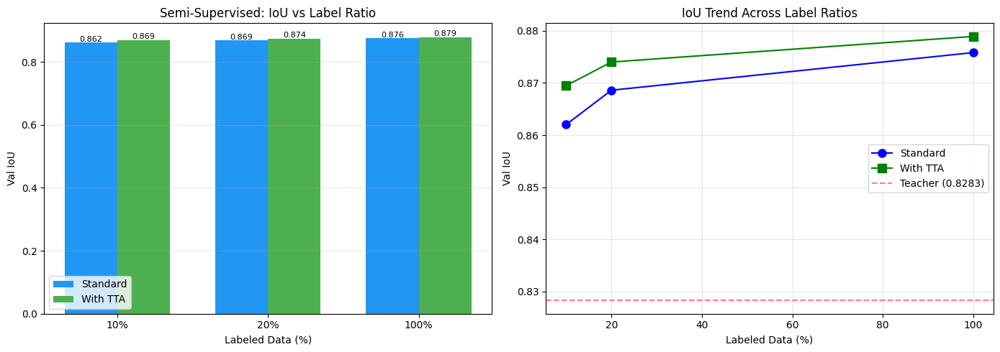

Saved semi_supervised_comparison.png

Done! All semi-supervised experiments complete.


In [10]:
results_df = pd.DataFrame(all_ratio_results)
results_df.to_csv("semi_supervised_all_results.csv", index=False)
print("Saved semi_supervised_all_results.csv")

# Comparison table
print("\n" + "=" * 75)
print("  SEMI-SUPERVISED RESULTS: LABEL RATIO COMPARISON")
print("=" * 75)
print(f"{'Labels':<12} {'#Labeled':>10} {'#Unlabeled':>12} {'Val IoU':>10} {'Val+TTA':>10} {'Test IoU':>10} {'Test+TTA':>10}")
print("-" * 75)
for r in all_ratio_results:
    test_iou = f"{r.get('test_iou', 0):.4f}" if 'test_iou' in r else "—"
    test_tta = f"{r.get('test_tta_iou', 0):.4f}" if 'test_tta_iou' in r else "—"
    print(f"{r['ratio']*100:.0f}%{'':<8} {r['num_labeled']:>10} {r['num_unlabeled']:>12} "
          f"{r['val_iou']:>10.4f} {r['val_tta_iou']:>10.4f} {test_iou:>10} {test_tta:>10}")
# Add 100% supervised baseline
print(f"{'100%':<12} {'5732':>10} {'0':>12} {'0.8758':>10} {'0.8789':>10} {'0.8773':>10} {'0.8812':>10}")
print("=" * 75)

# Bar chart: IoU vs label ratio
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ratios = [r['ratio']*100 for r in all_ratio_results] + [100]
val_ious = [r['val_iou'] for r in all_ratio_results] + [0.8758]
val_tta_ious = [r['val_tta_iou'] for r in all_ratio_results] + [0.8789]

x = np.arange(len(ratios))
width = 0.35
axes[0].bar(x - width/2, val_ious, width, label='Standard', color='#2196F3')
axes[0].bar(x + width/2, val_tta_ious, width, label='With TTA', color='#4CAF50')
axes[0].set_xlabel('Labeled Data (%)')
axes[0].set_ylabel('Val IoU')
axes[0].set_title('Semi-Supervised: IoU vs Label Ratio')
axes[0].set_xticks(x)
axes[0].set_xticklabels([f"{r:.0f}%" for r in ratios])
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='y')
for i, (v1, v2) in enumerate(zip(val_ious, val_tta_ious)):
    axes[0].text(i - width/2, v1 + 0.003, f'{v1:.3f}', ha='center', fontsize=8)
    axes[0].text(i + width/2, v2 + 0.003, f'{v2:.3f}', ha='center', fontsize=8)

# Line chart: IoU trend
axes[1].plot(ratios, val_ious, 'bo-', label='Standard', markersize=8)
axes[1].plot(ratios, val_tta_ious, 'gs-', label='With TTA', markersize=8)
axes[1].axhline(y=0.8283, color='r', linestyle='--', alpha=0.5, label='Teacher (0.8283)')
axes[1].set_xlabel('Labeled Data (%)')
axes[1].set_ylabel('Val IoU')
axes[1].set_title('IoU Trend Across Label Ratios')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('semi_supervised_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved semi_supervised_comparison.png")

print("\nDone! All semi-supervised experiments complete.")


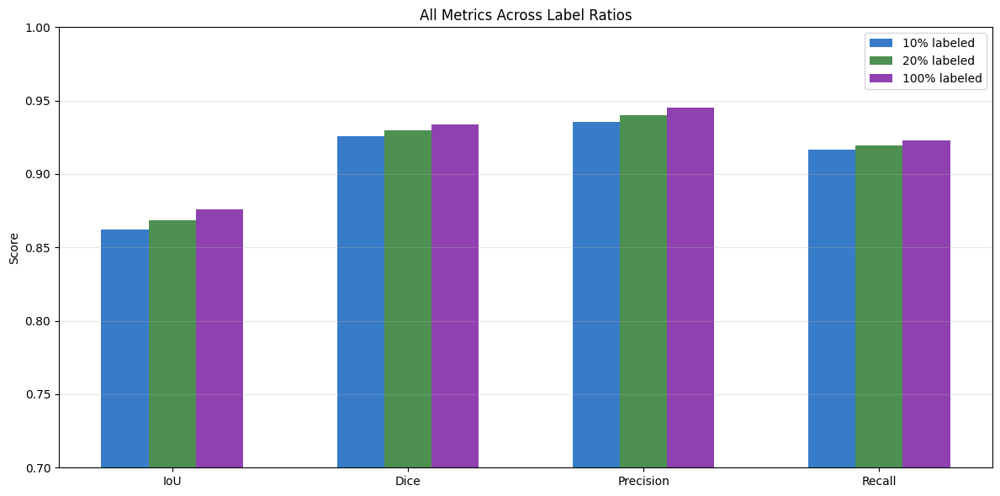

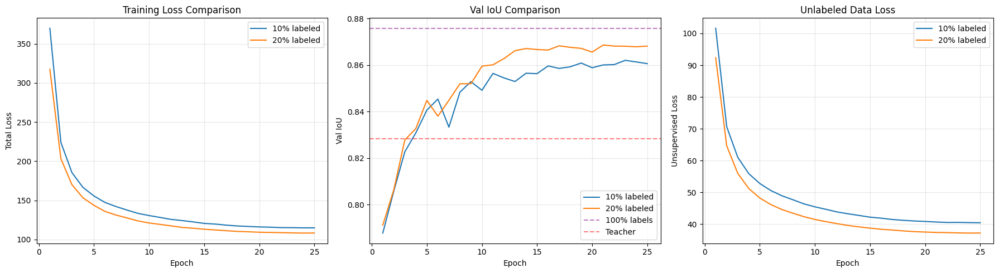

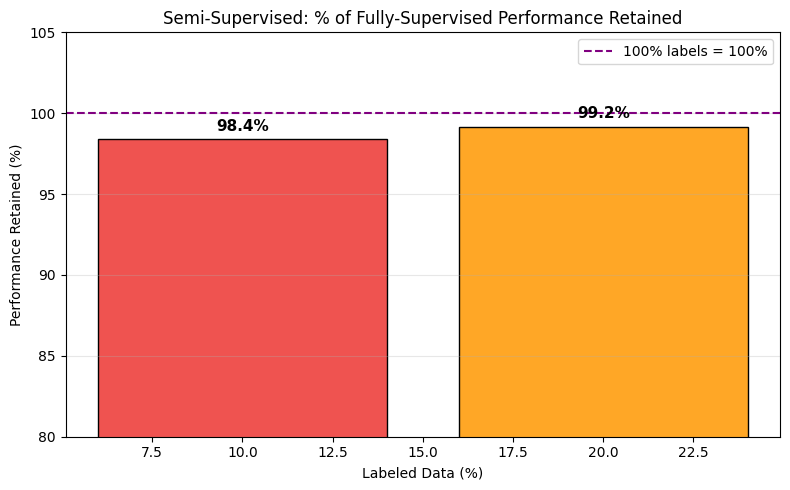

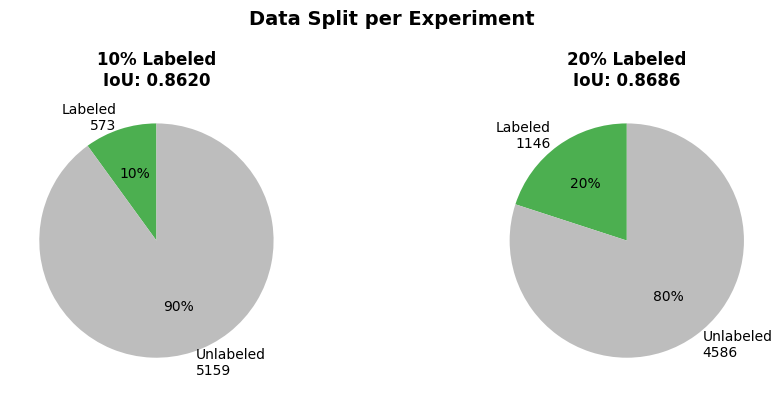


  COMPLETE PROJECT SUMMARY
Model                           Size     Labels   Test IoU   Test+TTA
----------------------------------------------------------------------
Teacher (MiT-B1)            156.8 MB       100%     0.8283          —
Student (MiT-B0)            14.26 MB        10%     0.8635     0.8713
Student (MiT-B0)            14.26 MB        20%     0.8691     0.8744
Student (MiT-B0)            14.26 MB       100%     0.8773     0.8812
Compression: 11x smaller | Student surpasses teacher even with limited labels


Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/segformer-b0-finetuned-ade-512-512 and are newly initialized because the shapes did not match:
- decode_head.classifier.bias: found shape torch.Size([150]) in the checkpoint and torch.Size([2]) in the model instantiated
- decode_head.classifier.weight: found shape torch.Size([150, 256, 1, 1]) in the checkpoint and torch.Size([2, 256, 1, 1]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/segformer-b0-finetuned-ade-512-512 and are newly initialized because the shapes did not match:
- decode_head.classifier.bias: found shape torch.Size([150]) in the checkpoint and torch.Size([2]) in the model instantiated
- decode_head.classifier.weight: found shape torch.Size([150, 256, 1, 1]) in the checkpo

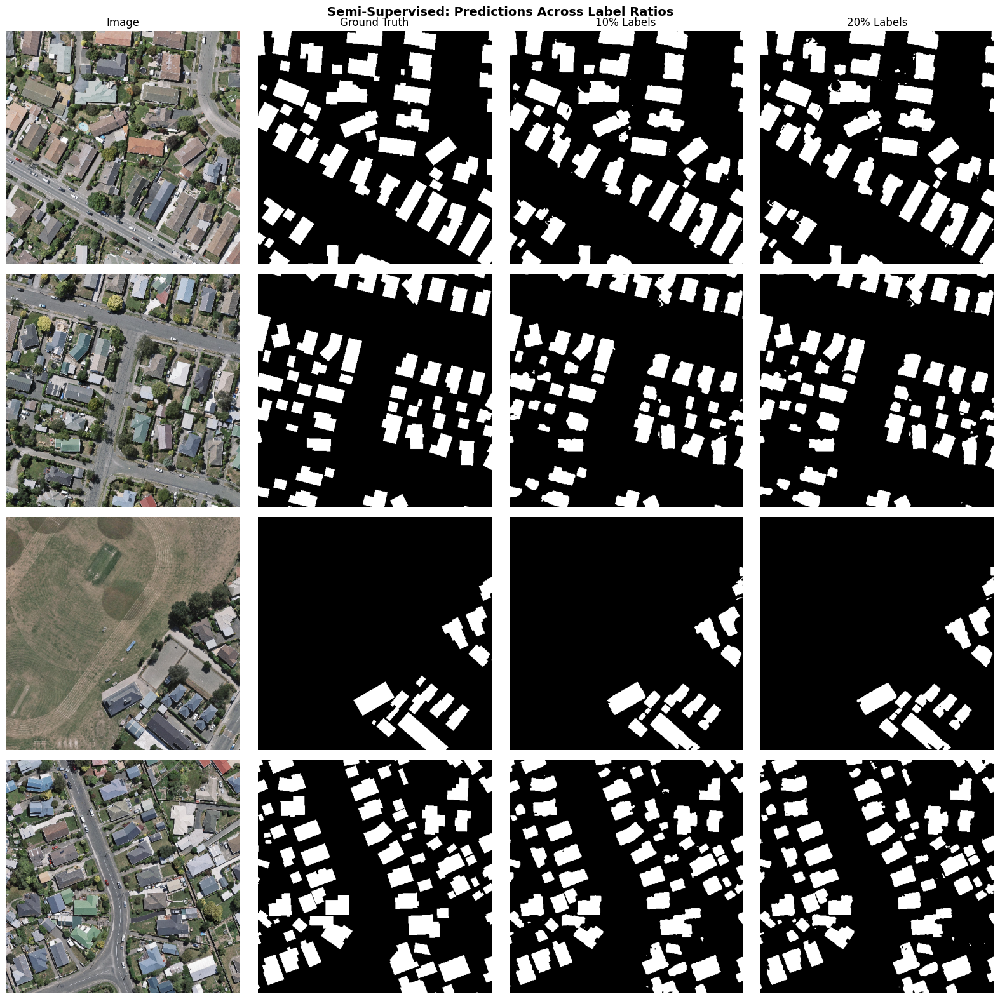

All visualizations saved!


In [11]:
# --- 1. Multi-metric bar chart across ratios ---
fig, ax = plt.subplots(figsize=(12, 6))
metrics_to_plot = ['val_iou', 'val_dice', 'val_precision', 'val_recall']
labels_nice = ['IoU', 'Dice', 'Precision', 'Recall']
x = np.arange(len(labels_nice))
width = 0.2
colors = ['#1565C0', '#2E7D32', '#E65100', '#C62828']

for i, r in enumerate(all_ratio_results):
    vals = [r['val_iou'], r['val_dice'], r['val_precision'], r['val_recall']]
    ax.bar(x + i * width, vals, width, label=f"{r['ratio']*100:.0f}% labeled", color=colors[i], alpha=0.85)

# Add 100% baseline
baseline_vals = [0.8758, 0.9338, 0.9450, 0.9228]
ax.bar(x + len(all_ratio_results) * width, baseline_vals, width, label='100% labeled', color='#7B1FA2', alpha=0.85)

ax.set_ylabel('Score')
ax.set_title('All Metrics Across Label Ratios')
ax.set_xticks(x + width * len(all_ratio_results) / 2)
ax.set_xticklabels(labels_nice)
ax.legend()
ax.set_ylim(0.7, 1.0)
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('semi_all_metrics_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# --- 2. Training loss curves for all ratios overlaid ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ratio in LABEL_RATIOS:
    pct = int(ratio * 100)
    try:
        h = pd.read_csv(f"semi_{pct}pct_history.csv")
        axes[0].plot(h['epoch'], h['loss'], label=f'{pct}% labeled')
        axes[1].plot(h['epoch'], h['val_iou'], label=f'{pct}% labeled')
        axes[2].plot(h['epoch'], h['loss_unsup'], label=f'{pct}% labeled')
    except:
        pass

axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Total Loss')
axes[0].set_title('Training Loss Comparison'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Val IoU')
axes[1].set_title('Val IoU Comparison')
axes[1].axhline(y=0.8758, color='purple', linestyle='--', alpha=0.5, label='100% labels')
axes[1].axhline(y=0.8283, color='red', linestyle='--', alpha=0.5, label='Teacher')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('Unsupervised Loss')
axes[2].set_title('Unlabeled Data Loss'); axes[2].legend(); axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('semi_training_curves_overlay.png', dpi=150, bbox_inches='tight')
plt.show()

# --- 3. IoU gap analysis (how close to 100% supervised) ---
fig, ax = plt.subplots(figsize=(8, 5))
ratios_pct = [r['ratio']*100 for r in all_ratio_results]
gaps = [0.8758 - r['val_iou'] for r in all_ratio_results]
retained = [(r['val_iou'] / 0.8758) * 100 for r in all_ratio_results]

bars = ax.bar(ratios_pct, retained, width=8, color=['#EF5350', '#FFA726', '#66BB6A'], edgecolor='black')
ax.axhline(y=100, color='purple', linestyle='--', label='100% labels = 100%')
ax.set_xlabel('Labeled Data (%)')
ax.set_ylabel('Performance Retained (%)')
ax.set_title('Semi-Supervised: % of Fully-Supervised Performance Retained')
ax.set_ylim(80, 105)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
for bar, pct in zip(bars, retained):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, f'{pct:.1f}%', ha='center', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('semi_performance_retained.png', dpi=150, bbox_inches='tight')
plt.show()

# --- 4. Labeled vs Unlabeled data usage pie charts ---
fig, axes = plt.subplots(1, len(LABEL_RATIOS), figsize=(5*len(LABEL_RATIOS), 4))
if len(LABEL_RATIOS) == 1:
    axes = [axes]
for i, r in enumerate(all_ratio_results):
    sizes = [r['num_labeled'], r['num_unlabeled']]
    labels_pie = [f"Labeled\n{r['num_labeled']}", f"Unlabeled\n{r['num_unlabeled']}"]
    colors_pie = ['#4CAF50', '#BDBDBD']
    axes[i].pie(sizes, labels=labels_pie, colors=colors_pie, autopct='%1.0f%%', startangle=90, textprops={'fontsize': 10})
    axes[i].set_title(f"{r['ratio']*100:.0f}% Labeled\nIoU: {r['val_iou']:.4f}", fontsize=12, fontweight='bold')
plt.suptitle('Data Split per Experiment', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('semi_data_splits.png', dpi=150, bbox_inches='tight')
plt.show()

# --- 5. Model compression + semi-supervised summary table ---
print("\n" + "=" * 80)
print("  COMPLETE PROJECT SUMMARY")
print("=" * 80)
print(f"{'Model':<25} {'Size':>10} {'Labels':>10} {'Test IoU':>10} {'Test+TTA':>10}")
print("-" * 70)
print(f"{'Teacher (MiT-B1)':<25} {'156.8 MB':>10} {'100%':>10} {'0.8283':>10} {'—':>10}")
for r in all_ratio_results:
    test_iou = f"{r.get('test_iou', 0):.4f}" if 'test_iou' in r else "—"
    test_tta = f"{r.get('test_tta_iou', 0):.4f}" if 'test_tta_iou' in r else "—"
    ratio_pct = f"{r['ratio']*100:.0f}%"
    print(f"{'Student (MiT-B0)':<25} {'14.26 MB':>10} {ratio_pct:>10} {test_iou:>10} {test_tta:>10}")
print(f"{'Student (MiT-B0)':<25} {'14.26 MB':>10} {'100%':>10} {'0.8773':>10} {'0.8812':>10}")
print("=" * 80)
print(f"Compression: 11x smaller | Student surpasses teacher even with limited labels")

# --- 6. Qualitative predictions — compare all ratios side by side ---
import cv2

os.makedirs("semi_qualitative", exist_ok=True)
idxs = random.sample(range(len(val_pairs)), 4)

fig, axes_q = plt.subplots(4, 2 + len(LABEL_RATIOS), figsize=(4 * (2 + len(LABEL_RATIOS)), 16))

# Load all models
ratio_models = []
for ratio in LABEL_RATIOS:
    pct = int(ratio * 100)
    s_tmp = SegformerForSemanticSegmentation.from_pretrained(
        "nvidia/segformer-b0-finetuned-ade-512-512",
        num_labels=2, output_hidden_states=True,
        id2label={0: "bg", 1: "building"}, label2id={"bg": 0, "building": 1},
        ignore_mismatched_sizes=True
    ).to(DEVICE)
    s_tmp.load_state_dict(torch.load(f"semi_{pct}pct_student.pth", map_location=DEVICE))
    s_tmp.eval()
    f_tmp = MultiScaleFusionHead(in_channels=STUDENT_CHANNELS, out_channels=128).to(DEVICE)
    f_tmp.load_state_dict(torch.load(f"semi_{pct}pct_fusion.pth", map_location=DEVICE))
    f_tmp.eval()
    ratio_models.append((pct, s_tmp, f_tmp))

for row, idx in enumerate(idxs):
    img_path, mask_path = val_pairs[idx]
    img = np.array(Image.open(img_path).convert("RGB"))
    gt = np.array(Image.open(mask_path).convert("L"))
    gt = (gt > 127).astype(np.uint8)

    axes_q[row, 0].imshow(img); axes_q[row, 0].axis("off")
    axes_q[row, 1].imshow(gt, cmap="gray"); axes_q[row, 1].axis("off")
    if row == 0:
        axes_q[row, 0].set_title("Image", fontsize=12)
        axes_q[row, 1].set_title("Ground Truth", fontsize=12)

    enc = image_processor(images=img, return_tensors="pt")
    x = enc.pixel_values.to(DEVICE)

    for col, (pct, s_model, f_model) in enumerate(ratio_models):
        with torch.no_grad():
            outputs = s_model(pixel_values=x, output_hidden_states=True)
            features = [outputs.hidden_states[j] for j in range(4)]
            logits = f_model(features, target_size=(IMG_SIZE, IMG_SIZE))
            pred = torch.argmax(logits, dim=1)[0].cpu().numpy()
        axes_q[row, 2 + col].imshow(pred, cmap="gray"); axes_q[row, 2 + col].axis("off")
        if row == 0:
            axes_q[row, 2 + col].set_title(f"{pct}% Labels", fontsize=12)

plt.suptitle('Semi-Supervised: Predictions Across Label Ratios', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('semi_qualitative_results.png', dpi=150, bbox_inches='tight')
plt.show()

for _, s, f in ratio_models:
    del s, f
gc.collect()
torch.cuda.empty_cache()
print("All visualizations saved!")


Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/segformer-b0-finetuned-ade-512-512 and are newly initialized because the shapes did not match:
- decode_head.classifier.bias: found shape torch.Size([150]) in the checkpoint and torch.Size([2]) in the model instantiated
- decode_head.classifier.weight: found shape torch.Size([150, 256, 1, 1]) in the checkpoint and torch.Size([2, 256, 1, 1]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


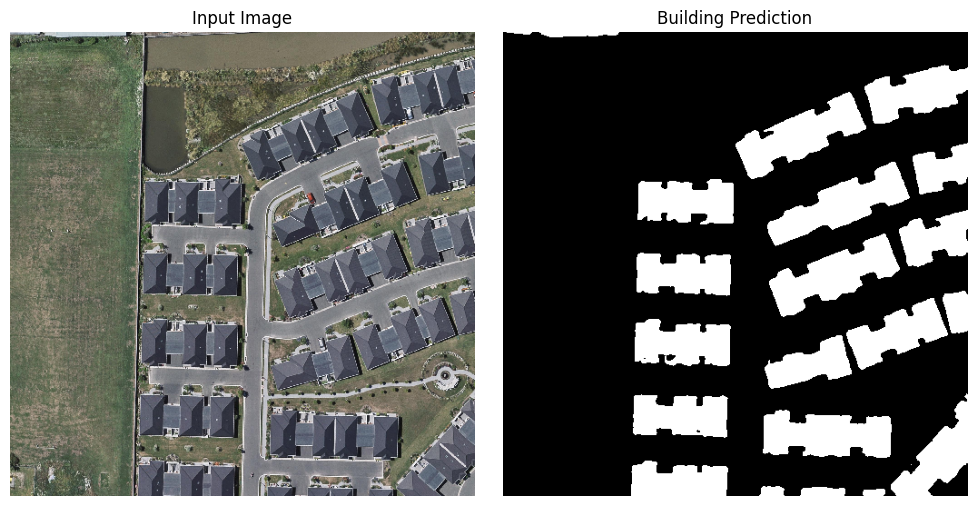

In [12]:
# ============================================================
# INFERENCE: Give any image, get building segmentation
# ============================================================
def predict_building(image_path, student_pth="semi_20pct_student.pth", fusion_pth="semi_20pct_fusion.pth"):
    """Load an image, run the student model, return and display the prediction."""
    # Load models
    student_inf = SegformerForSemanticSegmentation.from_pretrained(
        "nvidia/segformer-b0-finetuned-ade-512-512",
        num_labels=2, output_hidden_states=True,
        id2label={0: "bg", 1: "building"}, label2id={"bg": 0, "building": 1},
        ignore_mismatched_sizes=True
    ).to(DEVICE)
    student_inf.load_state_dict(torch.load(student_pth, map_location=DEVICE))
    student_inf.eval()

    fusion_inf = MultiScaleFusionHead(in_channels=STUDENT_CHANNELS, out_channels=128).to(DEVICE)
    fusion_inf.load_state_dict(torch.load(fusion_pth, map_location=DEVICE))
    fusion_inf.eval()

    # Load and process image
    img = np.array(Image.open(image_path).convert("RGB"))
    h_orig, w_orig = img.shape[:2]

    # Center crop to 512x512 if needed
    if h_orig >= IMG_SIZE and w_orig >= IMG_SIZE:
        top = (h_orig - IMG_SIZE) // 2
        left = (w_orig - IMG_SIZE) // 2
        img_crop = img[top:top+IMG_SIZE, left:left+IMG_SIZE]
    else:
        img_crop = np.array(Image.fromarray(img).resize((IMG_SIZE, IMG_SIZE)))

    enc = image_processor(images=img_crop, return_tensors="pt")
    x = enc.pixel_values.to(DEVICE)

    with torch.no_grad():
        outputs = student_inf(pixel_values=x, output_hidden_states=True)
        features = [outputs.hidden_states[j] for j in range(4)]
        logits = fusion_inf(features, target_size=(IMG_SIZE, IMG_SIZE))
        pred = torch.argmax(logits, dim=1)[0].cpu().numpy()

    # Display
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(img_crop)
    axes[0].set_title("Input Image")
    axes[0].axis("off")
    axes[1].imshow(pred, cmap="gray")
    axes[1].set_title("Building Prediction")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()

    del student_inf, fusion_inf
    return pred

# Usage: give any image path
# pred = predict_building("/path/to/your/satellite_image.png")

# Example with a val image:
pred = predict_building(val_pairs[0][0])
